In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes', 'gymnasium']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact'), 'gymnasium': ('1.2.3', 'gymnasium[toy-text]==1.2.3', 'gymnasium[toy-text]==1.2.3', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Deep Q-Networks

In that section an agent learned a table of action values one transition at a time, from transitions that any behavior could have produced. In that section we replaced a policy table by a network and trained it on CartPole. Doing the same for Q-learning looks like a one-line change: let a network output the two action values and keep the update. For the policy gradient the swap cost nothing, because nothing in its derivation used the table. For Q-learning the table sits inside the target, $r + \gamma \max_{a'} Q(s', a')$. Once the table is a network, every update moves the target together with the prediction, one update changes the values of states it never visited, and the contraction argument that made the tabular method converge no longer applies. Can a network keep the table's licence to learn from any transition?

In 2013 a group at DeepMind made the swap work: one network, with one set of hyperparameters, learned to play dozens of Atari games from the screen pixels, many of them about as well as a human tester [@mnih2013playing; @mnih2015human]. They called it a Deep Q-Network (DQN). Two devices kept it stable, a store of past transitions to train on and a frozen copy of the network to compute targets from. Both have been part of almost every off-policy deep method since. They also give the agent what the preceding sections could not: actor-critic used each batch once and PPO for a few epochs, while DQN trains on every transition it has stored, many times over.

We first show why the naive swap can fail, on a seven-state example whose weights grow without bound although there is no sampling noise. We then build DQN on CartPole, remove the frozen copy to see what it prevents, and end with the bias that the maximum in the target creates and a small change that reduces it. that section replaced that maximum by a soft one; here it stays hard.

In [ ]:
# Deterministic XLA kernels. On an accelerator XLA otherwise picks each
# matrix product's kernel by timing candidates, and kernels that add in
# different orders differ in the last bits; training runs at large step
# sizes can turn such differences into different outcomes. JAX reads
# XLA_FLAGS once, when it starts, so this cell runs before the imports.
import os
os.environ['XLA_FLAGS'] = (os.environ.get('XLA_FLAGS', '') +
                           ' --xla_gpu_deterministic_ops=true').strip()

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

In [ ]:
import gymnasium as gym

We again use CartPole with discount $0.99$, but specify the training budget as $50{,}000$ environment steps because episode length changes as the policy improves. The agent takes one gradient step after every two environment steps, on a minibatch of 128 stored transitions. Its Q-network maps a state through two hidden layers of 128 units to one value per action, and the greedy action is the argmax. Exploration is $\epsilon$-greedy, with $\epsilon$ falling linearly from 1 to 0.05 over the first 10,000 steps, the `linear_schedule` of that section. `make_env` builds the environment and `make_qnet(seed)` a seeded Q-network. Their argument `copies` offers each action several times; it serves the last experiment of the section and is 1 until then.

In [ ]:
gamma, num_env_steps, num_seeds = 0.99, 50_000, 3
buffer_size, batch_size, lr = 200_000, 128, 1e-3
train_freq, sync_every, warmup, grad_clip = 2, 250, 1_000, 10.0
epsilon = d2l.linear_schedule(1.0, 0.05, 10_000)

def make_env(copies=1):
    """CartPole; with copies > 1 each of its two actions is offered `copies`
    times (action a moves the cart as action a % 2), which leaves Q* as is."""
    env = gym.make('CartPole-v1')
    return env if copies == 1 else gym.wrappers.TransformAction(
        env, lambda a: a % 2, gym.spaces.Discrete(2 * copies))

In [ ]:
def make_qnet(seed, copies=1):
    """A seeded Q-network with one output per action."""
    rngs = nnx.Rngs(seed)
    return nnx.Sequential(d2l.Linear(4, 128, rngs=rngs), jax.nn.relu,
                          d2l.Linear(128, 128, rngs=rngs), jax.nn.relu,
                          d2l.Linear(128, 2 * copies, rngs=rngs))

The Q-network's layers are `d2l.Linear`, whose uniform initialization that section describes. With Flax's default initialization this DQN solved CartPole on fewer seeds in our runs.

## Sources of Instability

### The Semi-Gradient Update

Replace the table of that section by a network $Q_w$ with parameters $w$, and the update stays what it was, a semi-gradient step toward the bootstrapped target. Sample a transition $(s, a, r, s')$, form the target

$$y = r + \gamma\, \big(1 - \mathbf{1}(s' \textrm{ terminal})\big) \max_{a'} Q_w(s', a'),$$

hold $y$ fixed, and take one optimizer step that moves $Q_w(s, a)$ toward $y$. The indicator removes the bootstrap when $s'$ ends the episode. Each step is a step of ordinary regression toward a fixed number. The sequence of steps is not descent on any fixed objective, though, because the number moves with $w$, which that section observed for every bootstrapped target. A falling loss therefore shows that the network fits its current targets, not that the targets are right.

For a table, the expected update is a damped step of value iteration, and the Bellman backup is a contraction (that section): it shrinks the largest error over all states by the factor $\gamma$. A network cannot represent every backed-up function, so each regression returns the function in its class closest to the targets. "Closest" is measured by least squares over the training data, in which the error at a state counts in proportion to how often the data visit it; for linear features this fit is a projection. The backup shrinks the largest error, while the fit shrinks a visitation-weighted average error. The two measures disagree, and a fit that reduces the weighted error can enlarge the error at a rarely visited state, which the next backup carries into the targets of the states that lead there. When the data come from the policy being evaluated, the two measures agree well enough for linear features to converge [@Tsitsiklis.VanRoy.1997]. With data from another policy, even linear features can diverge.

### Correlated Data and Moving Targets

Two couplings make the network case harder in practice than the table case. The first is in the data. Consecutive transitions of one episode are nearly identical, since the cart and pole move only slightly from one step to the next, so training on the stream as it arrives updates a narrow region of the state space many times in a row. A table changes only the visited entry, so correlation only slows it down. A network changes its predictions at many states with every step (the figure), so a run of similar updates can overwrite what it learned elsewhere.

The second coupling is in the targets. The target $y$ contains $Q_w$, so every optimizer step changes both the prediction and the number it is regressed toward. The critic of that section had the same coupling, but it was refitted on fresh transitions of the current policy after every update, so an error at the states the policy visits was soon exposed and corrected.

### The Deadly Triad and Baird's Counterexample

Three ingredients meet in the network version of Q-learning: *function approximation*, *bootstrapping*, and *off-policy data*, that is, data collected by a policy other than the one whose values are learned. the figure places the algorithms of this chapter and the last by the ingredients they use. Each region with two ingredients holds a method that converges under its own conditions. Tabular Q-learning bootstraps from off-policy data and converges under the step-size conditions of that section. Linear temporal-difference learning, the critic of actor-critic in its simplest form, bootstraps with function approximation and converges for linear features when the data come from the evaluated policy. Behavior cloning fits a network to off-policy data without bootstrapping, which is supervised regression to fixed labels. These are sufficient conditions, not a theorem about pairs: nonlinear temporal-difference learning can diverge even on-policy [@Tsitsiklis.VanRoy.1997]. The name *deadly triad* refers to all three ingredients at once [@Sutton.Barto.2018; @vanHasselt.Doron.Strub.ea.2018].

Baird's counterexample isolates the triad in a seven-state linear problem [@Baird.1995]. Every reward is zero, so the true value function is zero and is represented exactly by $w = 0$. The computation uses expected temporal-difference updates, so there is no sampling noise. It weights the seven states uniformly, an off-policy distribution, while it evaluates a policy that always moves to state 7:

sup norm of w after 0, 500, 1000 sweeps: 10, 77, 335
the value the weights claim for state 7: 677, true value 0


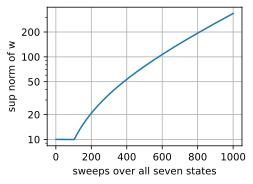

In [3]:
w = np.ones(8)                             # eight weights for seven states
w[6] = 10.0                                # the classic starting point
Phi = np.zeros((7, 8))                     # linear values v = Phi w
Phi[:6, :6], Phi[:6, 7] = 2 * np.eye(6), 1.0   # v(i) = 2 w_i + w_8
Phi[6, 6], Phi[6, 7] = 1.0, 2.0                # v(7) = w_7 + 2 w_8
sup = []
for _ in range(1000):
    v = Phi @ w                            # every reward is 0
    delta = gamma * v[6] - v               # the next state is always state 7
    w += 0.01 * (delta[:, None] * Phi).mean(0)   # uniform state weighting
    sup.append(np.abs(w).max())
print(f'sup norm of w after 0, 500, 1000 sweeps: 10, {sup[499]:.0f}, '
      f'{sup[-1]:.0f}')
print(f'the value the weights claim for state 7: {(Phi @ w)[6]:.0f}, '
      f'true value 0')
d2l.plot(np.arange(1, 1001), sup, 'sweeps over all seven states',
         'sup norm of w', yscale='log')

After a transient, the weights grow by a factor per sweep that settles to a constant: after a thousand sweeps their sup norm has grown from $10$ to $335$, and the value that the weights claim for state 7 is $677$, although its true value is zero. No sampling error is involved, and a smaller step size slows the divergence but does not remove it. Since the true value function is representable, the cause is not an approximation error either. Under the off-policy weighting, the expected update has a direction along which the weights grow [@Sutton.Barto.2018]. Weighting the states by the evaluated policy's own visits instead stops the divergence, although the values it reaches are wrong at the states that this weighting never visits (exercise 1).

Replay and target networks do not remove an ingredient of the triad. They reduce temporal correlation and slow the changes of the targets, which makes training much more stable in practice but does not restore a general convergence guarantee.

![The deadly triad. Each circle is one ingredient, and every region is occupied by an algorithm these two chapters have taught; the center, all three ingredients at once, is where DQN and offline Q-learning live, and where Baird's counterexample shows that divergence is possible. Drop any one ingredient and a convergence argument becomes available, each under its own step-size, coverage and representation conditions: the triad is a warning pattern, not an if-and-only-if theorem.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rl-deadly-triad.svg)

## Replay and Target Networks

DQN answers the two couplings with two devices, one for each. the figure shows how they fit together.

![Deep Q-learning as a data flow. The behavior policy acts with the online network; transitions enter the replay buffer, and uniformly sampled minibatches scramble time, which makes the data nearly independent and reusable. The regression target is computed by a frozen copy of the network, refreshed every $C$ steps, so the targets stand still between syncs. The gradient flows along exactly one path, into the online network; the marked edge from the frozen copy carries no gradient. Each stored transition carries the flag $\mathrm{term}$, and the mask $1 - \mathrm{term}$ in the target stops the bootstrap only at a true termination. The drawn buffer is full and evicting its oldest entries, the steady state of a long run; in this section's runs the 50,000-step budget never fills the 200,000-slot ring, so nothing is evicted.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rl-dqn-dataflow.svg)

### Experience Replay

The remedy for correlated data is an *experience replay buffer* [@Lin.1992]. Every transition is stored in a large array, and each training minibatch is drawn uniformly from the array. A minibatch then combines transitions collected at different times, and each transition is used in many updates. Q-learning permits this because the target for $(s, a, r, s')$ does not depend on the policy that chose $a$. Replay has a drawback: most stored transitions were collected by older policies, so an error in the targets can persist over many updates until the current behavior revisits the states where it lives.

`ReplayBuffer` keeps the five fields of a transition in preallocated arrays: the state, the action, the reward, the next state, and the flag `term` that records termination. `add` writes a transition at the next free slot, overwriting the oldest one once the array is full, and `sample` draws `batch_size` slots uniformly and returns them as the `Batch` of that section:

In [ ]:
class ReplayBuffer:
    """A ring of transitions in preallocated numpy; sample() returns a Batch."""
    def __init__(self, capacity, obs_dim):
        self.obs = np.zeros((capacity, obs_dim), np.float32)
        self.act = np.zeros(capacity, np.int64)
        self.rew = np.zeros(capacity, np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), np.float32)
        self.term = np.zeros(capacity, np.float32)
        self.capacity, self.size, self.ptr = capacity, 0, 0

    def add(self, obs, act, rew, next_obs, term):
        i = self.ptr
        self.obs[i], self.act[i], self.rew[i] = obs, act, rew
        self.next_obs[i], self.term[i] = next_obs, term
        self.ptr, self.size = (i + 1) % self.capacity, min(self.size + 1,
                                                           self.capacity)

    def __len__(self):
        return self.size

    def sample(self, batch_size, rng):
        """batch_size transitions drawn uniformly, each a one-step
        fragment: ep_ends marks every transition as its own episode."""
        i = rng.integers(self.size, size=batch_size)
        return d2l.Batch(self.obs[i], self.act[i], self.rew[i],
                         self.next_obs[i], self.term[i],
                         np.arange(1, batch_size + 1))

The capacity in this section is $200{,}000$ transitions, larger than the $50{,}000$-step budget, so no transition is evicted; exercise 5 studies a smaller buffer. `sample` declares every transition an episode fragment of length one, because a uniform draw has no episode order. On such a batch `reward_to_go` is the reward itself, and the `truncation_bootstrap` of that section adds $\gamma (1 - \mathrm{term})\, \hat{V}(s')$ for a given value estimate $\hat V$, so their sum is the one-step target that `td_target` from that section computes. Replay leaves only the one-step target, which is why it pairs with one-step bootstrapping. An $n$-step target needs consecutive transitions, so the buffer would have to keep their order (exercise 7).

### The Target Network

The remedy for moving targets is the *target network* [@mnih2015human]. A frozen copy $Q_{w^-}$ of the online network computes every bootstrap,

$$y = r + \gamma\, \big(1 - \mathbf{1}(s' \textrm{ terminal})\big) \max_{a'} Q_{w^-}(s', a'),$$

and the copy is synchronized with the online weights, $w^- \leftarrow w$, every $C$ environment steps, here 250. Between synchronizations the targets stand still, and the online network solves an ordinary regression problem. Predictions feed back into targets once per synchronization instead of once per gradient step. The critic of that section bootstrapped from its newest weights, because each batch was fresh; replay removes that freshness, and DQN accepts targets a few hundred steps old in exchange for a regression problem that changes slowly.

Two further controls bound the size of a step. The Huber loss is quadratic for residuals below 1 and linear above, so its derivative with respect to the prediction never exceeds 1. The full gradient also contains $\nabla_w Q_w(s, a)$, which the Huber loss does not bound, so the update clips the norm of the parameter gradient at 10, the default of Stable-Baselines3 rather than of the original paper [@Raffin.Hill.Gleave.ea.2021]. In code, `q_values` runs the network on a NumPy state without recording gradients, `fit_q` takes one clipped Huber step of $Q_w(s, a)$ toward fixed targets $y$, and `q_step` is the DQN update: the targets are `batch.td_target` with the bootstrap $\max_{a'} Q_{w^-}(s', a')$ of the frozen copy.

In [ ]:
def fit_q(qnet, opt, obs, act, y):
    """One Huber regression step of Q_w(s, a) toward the fixed y; traced
    inside the jitted steps, with the norm clip in the optimizer chain."""
    _, grads = nnx.value_and_grad(lambda q: optax.huber_loss(
        jnp.take_along_axis(q(obs), act[:, None], -1).squeeze(-1),
        y).mean())(qnet)
    opt.update(qnet, grads)

@nnx.jit
def q_step(qnet, target, opt, obs, act, rew, next_obs, term):
    """The DQN update: the critic's own td_target, bootstrapped by the copy."""
    batch = d2l.Batch(obs, act, rew, next_obs, term, None)
    fit_q(qnet, opt, obs, act,
          batch.td_target(lambda s: target(s).max(-1), gamma))

q_values = d2l.forward_np   # the acting forward: numpy in, numpy out

`q_values` is `d2l.forward_np`, which compiles one forward pass per network structure (that section). The norm clip is part of the optimizer chain, and `q_step` is compiled with the `td_target` computation inside it. A compiled function takes arrays, not a `d2l.Batch`, so `q_step` receives the batch's columns and rebuilds a `Batch` inside only to call `td_target`.

### The Training Loop

The parts of the learner that differ between frameworks come from `make_learner`: the frozen copy, the optimizer, `update`, which takes one step of the update rule `step` on a sampled batch, and `sync`, which copies the online weights into the frozen copy.

In [ ]:
def make_learner(qnet, step):
    """DQN's moving parts: the frozen copy, Adam with the norm clip, the
    update and the sync; the jitted step is bound to them once per run."""
    target = nnx.clone(qnet)
    opt = nnx.Optimizer(qnet, optax.chain(
        optax.clip_by_global_norm(grad_clip), optax.adam(lr)), wrt=nnx.Param)
    step_fn = nnx.cached_partial(step, qnet, target, opt)
    update = lambda b: step_fn(*map(jnp.asarray, (b.obs, b.act, b.rew,
                                                  b.next_obs, b.term)))
    sync = lambda: nnx.update(target, nnx.state(qnet, nnx.Param))
    return update, sync

`nnx.cached_partial` binds the network, its copy and the optimizer to the compiled step once, so the loop does not traverse the modules at every call.

The loop acts $\epsilon$-greedily with `epsilon_greedy` of that section, which takes a random action with probability $\epsilon$ and the argmax otherwise, stores every transition, and after the warm-up of 1,000 steps calls `update` on a sampled minibatch every second step. One switch sets up the experiment of this section. With `use_target=True` the copy is refreshed every `sync_every` steps. With `use_target=False` it is refreshed after every step, so the target is computed by the online network itself, the naive recipe without a target network. The argument `step` selects the update rule, and `copies` the number of copies of each action. At the end of every episode the generator yields the step count, the episode's return, and the network's estimate $\max_a Q_w(s_0, a)$ at the centered start state $s_0 = \mathbf{0}$.

In [ ]:
def train_dqn(seed, qnet, use_target=True, step=q_step, copies=1):
    """DQN on CartPole; yields (env step, episode return, max_a Q(s0, a))."""
    rng, env = np.random.default_rng(seed), make_env(copies)
    update, sync = make_learner(qnet, step)
    buffer, s0 = ReplayBuffer(buffer_size, 4), np.zeros(4, np.float32)
    obs, ep_return = env.reset(seed=seed)[0], 0.0
    for t in range(1, num_env_steps + 1):
        a = d2l.epsilon_greedy(q_values(qnet, obs), epsilon(t), rng)
        next_obs, rew, terminated, truncated, _ = env.step(a)
        buffer.add(obs, a, rew, next_obs, float(terminated))
        obs, ep_return = next_obs, ep_return + rew
        if terminated or truncated:
            yield t, ep_return, q_values(qnet, s0).max()
            obs, ep_return = env.reset()[0], 0.0
        if len(buffer) >= warmup and t % train_freq == 0:
            update(buffer.sample(batch_size, rng))
        if t % (sync_every if use_target else 1) == 0:
            sync()

The buffer stores `terminated`, never `truncated`. A CartPole episode cut off at 500 steps ends in a state that has a future, and that section showed that masking the bootstrap there teaches the network that surviving is worthless; exercise 3 traces what would go wrong.

### The Target-Network Ablation

Is the frozen copy needed? We train three seeds of each arm, identical except for the switch. Statements below about how often something happens across seeds were checked over twenty seeds per arm. The networks are built outside the training loop so that later cells can evaluate the trained agents. `train_checked` wraps `train_dqn`. It collects the per-episode records and, at the first episode end past every multiple of 5,000 environment steps, runs the *greedy policy*, which always takes $\mathrm{argmax}_a Q_w(s, a)$, for ten episodes on a separate copy of the environment, and once more at the end of the budget; `d2l.evaluate` is the Monte Carlo evaluation of that section, which averages the returns of a policy over a number of episodes, and `greedy` turns a Q-network into such a policy. These checks do not change training; we read them once the value estimates are understood.

In [ ]:
def greedy(qnet):
    """The greedy policy of a Q-network, (obs, rng) -> argmax_a Q(obs, a)."""
    return lambda s, rng: int(q_values(qnet, s).argmax())

def train_checked(seed, qnet, every=5_000, episodes=10, **kwargs):
    """train_dqn, plus a greedy evaluation over a few episodes at the first
    episode end past every multiple of `every` steps, and one at the end."""
    env, run, checks = make_env(kwargs.get('copies', 1)), [], []
    env.reset(seed=10_000 + seed)
    for t, ret, v0 in train_dqn(seed, qnet, **kwargs):
        run.append((t, ret, v0))
        if t >= every * (len(checks) + 1):
            checks.append(d2l.evaluate(env, greedy(qnet), episodes))
    checks.append(d2l.evaluate(env, greedy(qnet), episodes))
    return run, checks

In [ ]:
arms = ('DQN', 'no target network')
qnets = {arm: [make_qnet(seed) for seed in range(num_seeds)] for arm in arms}
runs, checks = {}, {}
for arm in arms:
    out = [train_checked(seed, qnets[arm][seed], use_target=arm == 'DQN')
           for seed in range(num_seeds)]
    runs[arm], checks[arm] = [r for r, _ in out], [c for _, c in out]

Seeds finish different numbers of episodes, so we plot against environment steps, the unit the budget is written in. `d2l.on_grid` resamples each run's per-episode records onto a common grid of environment steps, and `d2l.plot_curves` draws the median over seeds with a band from the lowest to the highest seed:

In [ ]:
grid = np.arange(1, num_env_steps // 1000 + 1) * 1000
d2l.plot_curves({arm: d2l.on_grid(runs[arm], grid, 1) for arm in runs},
                x=grid / 1000, xlabel='thousand environment steps',
                ylabel='return of the behavior policy', smooth=5,
                reference=500)

With a target network every seed improves from the random policy's return of about 20 to returns in the hundreds, although the curves stay ragged. The behavior return understates the policy, because the final exploration rate $\epsilon = 0.05$ still forces a random action on one step in twenty. Without a target network the return never rises above the random policy's and soon falls to about 9, the length of an episode in which the cart is pushed the same way at every step.

The value estimates show what went wrong. The training loop records $\max_a Q_w(s_0, a)$ at the centered start state, and we can say in advance where it should end. The buffer masks the bootstrap only on `terminated`, so the update keeps bootstrapping across the 500-step limit, and the state contains no clock. The network therefore learns the value of a continuing task, in which the time limit stops data collection but not the process. A policy that balances the pole forever earns $\sum_t \gamma^t = 1/(1-\gamma) = 100$ from the start, and no policy earns more, because every step pays 1. The dashed line marks this ceiling:

In [ ]:
ceiling = 1 / (1 - gamma)
d2l.plot_curves({'DQN': d2l.on_grid(runs['DQN'], grid, 2)},
                x=grid / 1000, xlabel='thousand environment steps',
                ylabel='value estimate at the start state',
                reference=ceiling)
print(f'continuing-task ceiling: {ceiling:.0f}; the no-target arm ends at ' +
      ', '.join(f'{np.asarray(r)[-1, 2]:.0e}' for r in
                runs['no target network']))

DQN's estimate climbs toward the ceiling, while the estimate without a target network passes $10^8$. The runaway goes up rather than in an arbitrary direction because CartPole pays 1 at every step. Every target of a transition that does not end the episode is $1 + \gamma \max_{a'} Q_w(s', a')$, one more than a discounted output of the network itself, and the shared parameters that lift $Q_w(s, a)$ toward it also lift $Q_w(s', \cdot)$, because $s'$ is close to $s$. The target stays ahead of the prediction at every step, and nothing stops the climb.

A frozen copy holds the target still for 125 gradient steps, so values can climb only one synchronization at a time. Suppose every value starts at zero and the online network fits its targets exactly between two synchronizations. Then after $n$ synchronizations no value exceeds

$$\sum_{k=0}^{n-1} \gamma^k = \frac{1 - \gamma^n}{1 - \gamma},$$

the discounted return of $n$ steps of reward 1. The budget holds about 196 synchronizations after the first gradient step, which bounds the start-state value by about 86. The plotted estimate follows this bound closely, a few points above it from about 10,000 steps on, and ends above 86 on every seed, because a network generalizes: a step that lifts the value of one state lifts its neighbors too, so value spreads faster than one backup per synchronization (exercise 6).

A target network is one repair for this feedback, not the only one. PQN [@Gallici.Fellows.Ellis.ea.2025] drops both the frozen copy and the replay buffer, normalizes the activations of every hidden layer, and collects data from many environments in parallel; exercise 10 tries the normalization on CartPole.

### Evaluation of the Greedy Policy

The return curve is a poor summary of a run. It includes the exploratory actions, its final value depends on when the run happens to stop, and its best value is chosen after looking at the whole curve, which flatters every method. We therefore evaluate the greedy policy at budgets fixed in advance. These are the checks that `train_checked` recorded, a ten-episode greedy return after every 5,000 environment steps and one at the end of the budget:

In [ ]:
print('greedy return (10 episodes) every 5,000 environment steps')
for arm in arms:
    for seed, c in enumerate(checks[arm]):
        print(f'{arm:>17}, seed {seed}: ' + ' '.join(f'{x:3.0f}' for x in c))

Checked this way, DQN's greedy policy sits mostly at a return of about 50 to 250 for the first 30,000 steps, with an occasional early check at 500, and then reaches 500 on most seeds between 35,000 and 45,000 steps. A good check is not final: some seeds later fall back by hundreds of points, as one seed of the printout does, and about half of the twenty did. Without a target network the greedy policy never lasts more than about 10 steps at any check, so training longer does not rescue it. Although DQN trains on each stored transition many times, it needs more environment steps to balance the pole for the full episode than PPO with four epochs per batch needed in that section.

A greedy return says how good the policy is, not whether the network knows how good it is. @Hasselt.Guez.Silver.2016 test a value estimate against the discounted return that the greedy policy actually earns, which is the quantity the estimate claims to predict. `audit` computes three numbers for a trained network: the greedy return over 100 episodes, the greedy policy's discounted return over 20 episodes (`d2l.evaluate` with `gamma`), and the estimate $\max_a Q_w(s_0, a)$. Episodes start close to the centered state, so the discounted return measures the value of $s_0$. Under the 500-step limit even a perfect policy earns only $(1 - \gamma^{500})/(1 - \gamma) \approx 99.3$, slightly less than the ceiling of the continuing task.

In [ ]:
def audit(qnet, seed, copies=1):
    """Greedy return over 100 episodes, its discounted return over 20, and
    the network's own estimate max_a Q(s0, a) of the latter."""
    env = make_env(copies)
    env.reset(seed=100 + seed)
    score = d2l.evaluate(env, greedy(qnet), 100)
    env.reset(seed=100 + seed)
    disc = d2l.evaluate(env, greedy(qnet), 20, gamma=gamma)
    return score, disc, q_values(qnet, np.zeros(4, np.float32)).max()

audits = {arm: [audit(qnets[arm][seed], seed) for seed in range(num_seeds)]
          for arm in arms}
for arm in arms:
    for seed, (score, disc, v0) in enumerate(audits[arm]):
        print(f'{arm:>17}, seed {seed}: return {score:3.0f}, discounted '
              f'{disc:5.1f}, max_a Q(s0) {v0:8.3g}')

Where the greedy policy balances the pole, the estimate sits within about eight points of the discounted return that the policy earns, usually below it, because the values are still climbing at the end of the budget: the plot of the start-state value above has not leveled off. Where the greedy policy fails, which happened on about two seeds in five, the estimate is above what the policy earns, by more than 20 points on about half of such runs. With two actions, these failing runs are the only sign of the network promising more than its policy delivers, too few and too mixed with other errors to measure the effect. A cleaner test needs a maximum over more actions.

## Overestimation

### The Maximization Bias in Numbers

The target the equation maximizes estimated action values. For noisy estimates, $\mathbb{E}[\max_{a'}\hat{Q}(s',a')]\geq\max_{a'}\mathbb{E}[\hat{Q}(s',a')]$, with strict inequality when the noise can change which action is largest. that section demonstrated this bias in a table, and that section showed that the hard maximum is the $\beta\to0$ limit of the soft backup with a uniform reference. With function approximation, the bias at one state feeds into the targets of the states that lead to it [@Thrun.Schwartz.1993].

The following simulation gives four actions the same true value of zero and adds independent unit noise to each estimate. The single estimator selects and evaluates an action with the same noisy values. The double estimator selects with one set of noisy values and evaluates with an independent second set [@vanHasselt.2010]:

In [13]:
rng = np.random.default_rng(0)
est = rng.standard_normal((100_000, 4))     # four values, all truly zero
second = rng.standard_normal((100_000, 4))  # an independent second estimate
sel = est.argmax(1)
print(f'single estimator, E[max of the estimates]: {est.max(1).mean():.3f}')
print(f'select with one, evaluate with the other: '
      f'{second[np.arange(100_000), sel].mean():+.3f}')

single estimator, E[max of the estimates]: 1.031
select with one, evaluate with the other: -0.006


The maximum of four unit-noise estimates has an upward bias of about one unit. With independent estimates for selection and evaluation, the evaluator's noise has mean zero whichever action was selected, and the measured bias is near zero. the figure shows that the single estimator's bias grows with the number of actions, while the independent double estimator stays at zero. A language model choosing its next token among $10^5$ actions would face a far larger bias from a maximum over noisy estimates, one reason why language-model post-training uses policy gradients rather than a Q-network. A fixed dataset makes the bias worse still, because no new interaction corrects an overrated action (that section).

![A maximum over noisy estimates is biased upward. Left: the distribution of the largest of four independent estimates of the same true value of zero, against the distribution of a single estimate; the maximum carries a measured bias of $1.03$. Right: the bias of the single estimator grows with the number of actions, while the bias of the independent double estimator, one set of estimates selecting the action and an independent set scoring it, is indistinguishable from zero throughout.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rl-max-bias.svg)

### Double DQN

The double estimator needs two value estimates, and DQN already has two networks. Double DQN [@Hasselt.Guez.Silver.2016] selects the action with the online network and evaluates it with the target network:

$$y = r + \gamma\, \big(1 - \mathbf{1}(s' \textrm{ terminal})\big)\ Q_{w^-}\big(s',\ \underset{a'}{\mathrm{argmax}}\ Q_w(s', a')\big).$$

An action that the online network overrates by chance is then scored by a different network. The change needs no new network, only one more forward pass of the online network on $s'$. The two networks are not independent, since the copy is the online network of at most 125 gradient steps earlier, so Double DQN removes only part of the bias. If the evaluating estimate is correlated with the selecting one with coefficient $\rho$, the bias that remains is $\rho$ times that of the single estimator (exercise 4). The change to `q_step` is three lines:

In [ ]:
@nnx.jit
def q_step_double(qnet, target, opt, obs, act, rew, next_obs, term):
    """q_step with selection split from evaluation, eq_double_dqn."""
    sel = qnet(next_obs).argmax(-1)
    batch = d2l.Batch(obs, act, rew, next_obs, term, None)
    fit_q(qnet, opt, obs, act, batch.td_target(lambda s: jnp.take_along_axis(
        target(s), sel[:, None], -1).squeeze(-1), gamma))

### Duplicated Actions

CartPole gives the maximum little to choose from. The bias of the larger of two independent unit-noise estimates is $1/\sqrt{\pi} \approx 0.56$, about half the four-action value, and the two-action estimates of the ablation are pulled the other way by the lag of the synchronizations. To see the bias on a trained network without changing the task, we offer each of CartPole's actions nine times. `make_env(copies=9)` exposes 18 actions, the size of the full Atari action set, and action $a$ pushes the cart the way action $a \bmod 2$ does; `make_qnet(seed, copies=9)` has 18 outputs. The duplicates change neither the optimal values nor the ceiling of 100. The 18 outputs are nine noisy estimates of each of two values, and the maximum in the target picks the luckiest of nine, the right panel of the figure on a real network. The next cell trains DQN and Double DQN with 18 actions, and Double DQN with two, and audits every trained network; DQN with two actions is the arm of the ablation:

In [ ]:
arms2 = {'Double DQN, 2 actions': (q_step_double, 1),   # (update, copies)
         'DQN, 18 actions': (q_step, 9),
         'Double DQN, 18 actions': (q_step_double, 9)}
names = ('DQN, 2 actions', *arms2)
qnets[names[0]], runs[names[0]] = qnets['DQN'], runs['DQN']
audits[names[0]] = audits['DQN']
for name, (step, copies) in arms2.items():
    qnets[name] = [make_qnet(seed, copies) for seed in range(num_seeds)]
    runs[name] = [list(train_dqn(seed, qnets[name][seed], step=step,
                                 copies=copies)) for seed in range(num_seeds)]
    audits[name] = [audit(qnets[name][seed], seed, copies)
                    for seed in range(num_seeds)]

For each arm we print, per seed, the greedy return, the greedy policy's discounted return and the start-state estimate:

In [ ]:
print(f'{"per seed:":>22} {"greedy return":>17}   {"discounted":>17}'
      f'   {"max_a Q(s0)":>17}')
for name in names:
    res = np.array(audits[name]).T
    print(f'{name:>22} ' + '   '.join(' '.join(f'{x:5.1f}' for x in row)
                                     for row in res))

The start-state estimates of the 18-action pair, against the ceiling, over training:

In [ ]:
d2l.plot_curves({name: d2l.on_grid(runs[name], grid, 2) for name in names[2:]},
                x=grid / 1000, xlabel='thousand environment steps',
                ylabel='value estimate at the start state',
                reference=ceiling)

With each action offered nine times, DQN's start-state estimate ends above the ceiling on every seed, typically 10 to 30 points above it. Where its greedy policy balances the pole and earns about 99, the estimate exceeds that return by about as much. No value the task allows lies above the ceiling, so the overestimation is certain without any further evaluation. In the plot, DQN's estimate crosses the ceiling before 40,000 steps and keeps rising, while Double DQN's stays near or below it. Double DQN's estimate ends 10 to 25 points lower on almost every seed, near the ceiling, although a seed whose policy fails can still overshoot. A few of the twenty 18-action DQN runs are still climbing at 50,000 steps, the bias feeding back through the bootstrap. With two actions the two targets agree within a few points, and at this budget neither arm's greedy return differs beyond the variation across seeds. On CartPole the double estimator makes the values more accurate without changing how well the greedy policy balances the pole.

We can now train a value network on transitions from any policy, replayed many times, with a frozen copy that keeps the targets still and a second estimate that keeps the maximum from inflating them. Both repairs assume that the maximum over actions can be computed: CartPole's two pushes and Atari's 18 joystick actions form a list. The torque of a motor is a number in an interval, and an argmax over it is an optimization problem of its own at every step. The next section keeps replay and the frozen copy, and replaces the maximum by a second network trained to propose the best action, which completes the off-policy column of the figure.

## Summary

A network in place of the Q-table combines function approximation, bootstrapping and off-policy data, and Baird's seven states show that this combination can diverge even when the true values are representable and no sampling noise is present. DQN keeps all three ingredients and repairs two couplings: a replay buffer breaks the correlation of consecutive transitions and reuses each of them many times, and a frozen target network holds the regression targets still between synchronizations. On CartPole, removing the frozen copy sends the start-state value past $10^8$; with it, the value climbs one synchronization at a time toward the ceiling of 100, and the greedy policy balances the pole for the full 500 steps on most seeds after 35,000 to 45,000 environment steps. The maximum in the target biases the values upward, more so the more actions it chooses among, and with each action offered nine times DQN's estimate ends above the ceiling on every seed. Double DQN selects the action with the online network and evaluates it with the frozen copy, which removes most of that bias at the cost of one extra forward pass.

## Exercises

1. [code] **Baird under on-policy weighting.** The computation of Baird's
   counterexample in that section weights the seven
   states equally through `.mean(0)`. In matrix form, one sweep is
   $\mathbf{w} \leftarrow \mathbf{w} + \alpha A \mathbf{w}$ with $\alpha = 0.01$ and

   $$A = \Phi^\top D (\gamma P - I) \Phi,$$

   where $D$ is the diagonal matrix of the state weights and $P$ is the
   transition matrix of the evaluated policy, every row of which puts all
   probability on state 7.
    1. Compute the eigenvalues of $A$ for $D = I/7$. Compare $1 + \alpha\lambda$,
       for the eigenvalue $\lambda$ with the largest real part, with the
       per-sweep growth factor of the sup norm of $\mathbf{w}$ late in a run
       of $20{,}000$ sweeps.
    1. The evaluated policy moves to state 7 and stays there, so its
       visitation distribution puts all weight on state 7. Rerun the
       iteration with this weighting. To which weights and which state values
       does it converge, and how do these values compare with the true
       values?
    1. Mix the two weightings, $\mathbf{d} = (1 - p)\,\mathbf{1}/7 + p\,\mathbf{e}_7$,
       and find by bisection the smallest $p$ for which no eigenvalue of $A$
       has a positive real part, for $\gamma \in \{0.9, 0.95, 0.99\}$.
       How does the amount of off-policy weight that the iteration tolerates depend on the
       discount?

1. **Huber loss and norm clipping.** `fit_q` regresses with the Huber loss
   of threshold 1, $\ell(e) = e^2/2$ for $|e| \leq 1$ and
   $\ell(e) = |e| - 1/2$ otherwise, where $e = Q_w(s, a) - y$ is the residual
   of one transition, and averages it over the $B$ transitions of a
   minibatch. The update then rescales the minibatch gradient to norm
   `grad_clip` $= 10$ whenever its norm exceeds 10 and passes it to Adam.
    1. Show that $\ell'(e) = \max\big(-1, \min(1, e)\big)$. In which sense
       is Huber regression squared-loss regression with clipped residuals?
    1. Show that the minibatch gradient has norm at most
       $\max_i \|\nabla_w Q_w(s_i, a_i)\|$, and explain why this bound can
       grow while every residual stays the same.
    1. Adam divides a running average of the gradients by the square root
       of a running average of their squares. Apart from the small constant
       it adds for numerical stability, multiplying every gradient of a run
       by one constant therefore leaves its steps unchanged. Which gradient
       sequences does the norm clip change? How does it change the Adam
       steps that follow a single gradient of very large norm, such as one
       that may follow a target-network synchronization?
    1. An Adam step moves each parameter by roughly the learning rate, here
       $10^{-3}$, whatever the size of its gradient. The run without a target
       network takes about $25{,}000$ such steps, and its start-state values
       reach about $10^8$. Estimate how far one parameter can travel during
       the run, and explain how steps of that size can produce values of
       $10^8$ in the three linear layers of `make_qnet`, whose hidden layers
       have 128 units.

1. **Terminated, not done.** `train_dqn` stores `float(terminated)`, so a
   transition into CartPole's 500-step time limit still bootstraps. Consider
   an implementation that stores `float(terminated or truncated)` instead.
    1. Which stored transitions does the change affect while the greedy
       policy still fails within a few hundred steps, and which once every
       episode reaches the limit?
    1. The observation contains no clock, so the network cannot tell a state
       at step 499 from a similar balanced state at step 50. Model its
       estimate on balanced states by a single number $q$, the value of a
       one-state task that pays reward 1 at every step and is cut off after
       $H$ steps. With the faulty mask, $H - 1$ of the $H$ transitions of an
       episode have the target $1 + \gamma q$ and the last one has the
       target $1$. Show that the fixed point of the averaged update is
       $q = H / \big(H - \gamma (H - 1)\big)$, and evaluate it at $H = 500$
       and $\gamma = 0.99$. The start-state value plot of
       that section marks $1/(1 - \gamma)$ as the ceiling.
       Compare $q$ with the value of the start state of a 500-step episode
       when the remaining time is known, $(1 - \gamma^{H})/(1 - \gamma)$.
       Which of the two is the ceiling of the faulty implementation for a
       network without a clock? What would a final estimate of $94$
       indicate?

1. [code] **Maximization bias in closed form.** Let the estimates
   $X_1, \ldots, X_m$ of $m$ actions with the same true value $0$ be jointly
   normal with variance $\sigma^2$ each.
    1. For $m = 2$ and independent estimates, show that
       $\mathbb{E}[\max(X_1, X_2)] = \sigma/\sqrt{\pi}$, using
       $\max(x, y) = (x + y)/2 + |x - y|/2$.
    1. The outputs of one network share its hidden layers, so their errors
       are correlated. For $m = 2$ and correlation $c$ between $X_1$ and
       $X_2$, show that the bias becomes $\sigma \sqrt{(1 - c)/\pi}$.
    1. In Double DQN, the target network evaluates the action that the online
       network selects, and the errors of the two networks are correlated.
       Model the evaluating estimate of action $a$ as
       $Y_a = \rho X_a + \sqrt{1 - \rho^2}\, Z_a$, where $Z_1, \ldots, Z_m$
       have mean zero and variance $\sigma^2$ each and are independent of
       $X_1, \ldots, X_m$, so that $Y_a$ has variance $\sigma^2$ and
       correlation $\rho$ with $X_a$. Show that the bias of
       $Y_{\mathrm{argmax}_a X_a}$ is $\rho\, \mathbb{E}[\max_a X_a]$.
    1. Check parts (a) and (c) by modifying the simulation of
       that section: use two actions, and draw the second
       estimate as `rho * est + np.sqrt(1 - rho**2) * noise` with fresh
       standard normal `noise`, for $\rho \in \{0, 0.5, 0.9\}$.

1. [code] **Replay reuse and buffer capacity.** ● Once the buffer holds
   `warmup` transitions, `train_dqn` takes one gradient step on
   `batch_size` $= 128$ uniformly sampled transitions every `train_freq`
   $= 2$ environment steps. With the default capacity, no transition is
   evicted.
    1. Show that a transition stored at step $t_0 \geq 1000$ is sampled about
       $64 \ln(50{,}000/t_0)$ times in expectation over the run, and evaluate
       this for $t_0 \in \{1000, 25{,}000, 49{,}000\}$. Data from which phase
       of training dominate the updates?
    1. With a capacity of 500 transitions, how often is a transition sampled
       in expectation while it stays in the full buffer? Compare this with
       part (a).
    1. Set `buffer_size` to $500$ and to $5000$, and lower `warmup` to 500
       for the smaller capacity, because `train_dqn` waits until the buffer
       holds `warmup` transitions. Train one seed for each capacity and
       compare the return curve and the start-state value trace with the
       default run. At which stage of training does the damage appear?
    1. A small buffer both correlates the transitions of a minibatch and
       discards old states. To separate the two effects, keep the default
       capacity and change `ReplayBuffer.sample` to return `batch_size`
       consecutive transitions from a uniformly drawn start index. Compare
       this run with the run at capacity 500. Which of the two effects
       accounts for the damage of part (c)?

1. [code] **The sync period.** ● `train_dqn` copies the online weights into
   the target network every `sync_every` $= 250$ environment steps, which is
   every 125 gradient steps.
    1. that section bounds every value after $n$
       synchronizations by $(1 - \gamma^n)/(1 - \gamma)$. Evaluate this bound
       at the end of the budget for `sync_every`
       $\in \{10, 50, 250, 1000, 5000\}$, counting the synchronizations that
       follow the first gradient step.
    1. Rerun the DQN arm with these five values, two seeds each, and record
       the greedy evaluation after the budget and the start-state value
       trace. Which end of the sweep behaves like the run without a target
       network? At which end does the bound of part (a) limit what the run
       can reach?
    1. The bound assumes that every value starts at zero and that the online
       network fits its targets exactly between synchronizations. With
       `sync_every` $= 250$, record $\max_a Q_w(s_0, a)$ just before each of
       the first 40 synchronizations of one seed and plot it against the
       bound. Where does the run first cross the bound, and which of the two
       assumptions does the crossing violate?

1. **n-step targets from replay.** ● Several successors of DQN replace the
   one-step target the equation by an $n$-step target, the
   $n$-step return of that section with a maximum at its end,

   $$y^{(n)}_t = \sum_{i=0}^{n-1} \gamma^i r_{t+i} + \gamma^n \max_{a'} Q_{w^-}(s_{t+n}, a'),$$

   written here for an episode that continues past step $t + n$.
    1. `ReplayBuffer.sample` returns isolated transitions. What must the
       buffer store, and how must `sample` choose its indices, so that
       $y^{(n)}_t$ can be formed?
    1. Write $y^{(n)}_t$ for an episode that terminates at step $t + j$ with
       $j < n$. How does it change when the episode is truncated at step
       $t + j$ instead?
    1. The actions $a_{t+1}, \ldots, a_{t+n-1}$ were chosen by the
       $\epsilon$-greedy behavior policy of an older network. For $n = 2$ and
       $Q_{w^-} = Q^*$, write $\mathbb{E}[y^{(2)}_t \mid s_t, a_t]$ and show that it
       equals the one-step target of $Q^*$ only if $a_{t+1}$ is greedy for
       $Q^*$ with probability one. Which policy's value does the $n$-step
       target estimate?
    1. The $n$-step returns of that section did not raise the
       question of part (c). Why not?

1. **Prioritized sampling.** ● Prioritized replay
   [@Schaul.Quan.Antonoglou.ea.2016] samples stored transition $i$ with
   probability $P(i)$ instead of $1/N$ and multiplies its loss by a weight
   $u_i$. Let $\mathbf{g}_i$ be the gradient of the loss of transition $i$,
   so that uniform replay estimates
   $\bar{\mathbf{g}} = \frac{1}{N} \sum_i \mathbf{g}_i$.
    1. Show that a single sampled transition with weight
       $u_i = 1/\big(N P(i)\big)$ gives an unbiased estimate of
       $\bar{\mathbf{g}}$.
    1. Find the distribution $P$ that minimizes the expected squared error
       $\mathbb{E}\|u_i \mathbf{g}_i - \bar{\mathbf{g}}\|^2$ of this estimate. For the
       squared loss, $\mathbf{g}_i = e_i \nabla_w Q_w(s_i, a_i)$ with residual
       $e_i$. Under which condition is sampling in proportion to $|e_i|$
       optimal?
    1. @Schaul.Quan.Antonoglou.ea.2016 sample with
       $P(i) \propto (|e_i| + c)^{p}$ for a small constant $c > 0$, and
       use the weights
       $u_i = \big(N P(i)\big)^{-q}$ divided by $\max_j u_j$, with
       $q$ annealed toward 1 over training; the exponents $p$ and $q$ are
       the paper's $\alpha$ and $\beta$. Which of the two changes to
       the weights of part (a) affects only the step size, and which changes
       the point to which the updates converge?

1. [code] **Baird with a target network.** ●● DQN computes its bootstrap
   from a frozen copy of the weights. In the computation of Baird's
   counterexample in that section, compute `delta` from
   a copy `w_target` as `gamma * (Phi @ w_target)[6] - Phi @ w`, and set
   `w_target = w.copy()` every $k$ sweeps.
    1. Run $100{,}000$ sweeps for $k \in \{1, 10, 30, 100, 300, 1000\}$ and
       plot both the sup norm of $\mathbf{w}$ and the largest value error
       $\max_i |(\Phi \mathbf{w})_i|$. For which $k$ does the iteration
       converge, and how does its speed depend on $k$? Why does the sup norm
       of $\mathbf{w}$ not approach zero where the values do?
    1. Show that the seven rows of `Phi` are linearly independent, so that
       every vector of target values is represented exactly by some
       $\mathbf{w}$. Deduce that if the regression between two
       synchronizations were solved exactly, each synchronization would map
       the values $\mathbf{v}$ to $\gamma P \mathbf{v}$ under every positive
       state weighting. Use this to explain both ends of part (a).
    1. In the counterexample of Tsitsiklis and Van Roy, two nonterminal
       states have values $w$ and $2w$ for one weight $w$, and every reward is
       zero. The first state moves to the second, and the second stays where
       it is with probability $1 - \xi$ and terminates otherwise. Weight both
       states equally. Show that exact least-squares regression to the targets
       of a frozen weight $w_k$ gives
       $w_{k+1} = \gamma (6 - 4\xi)\, w_k / 5$, and that the semi-gradient
       iteration without a target network diverges under the same condition
       on $\gamma$ and $\xi$.
    1. Both examples contain all three ingredients of the triad. Which
       property of the function class separates the example that a target
       network repairs from the one that it cannot repair?

    *Adapted from Richard S. Sutton and Andrew G. Barto,
    [Reinforcement Learning: An Introduction](http://incompleteideas.net/book/RLbook2020.pdf),
    Example 11.1.*

1. [extended] **LayerNorm instead of a target network.** ●●
   @Gallici.Fellows.Ellis.ea.2025 prove that a sufficiently wide
   Q-network with LayerNorm, trained with an $\ell_2$ penalty on its
   final-layer weights, satisfies a stability condition for
   temporal-difference learning without a target network, even on off-policy
   data. In their experiments, LayerNorm alone sufficed in every environment
   except Baird's counterexample.
    1. Insert a LayerNorm after each hidden linear layer of `make_qnet`,
       before the ReLU, and rerun the arm without a target network on three
       seeds. Compare the start-state value traces and the greedy evaluations
       with both arms of that section.
    1. Add the same layers to the DQN arm, which keeps its target network.
       What does LayerNorm change there?
    1. If a seed of part (a) still diverges, add an $\ell_2$ penalty on the
       weights of the last linear layer and find the smallest coefficient
       that prevents divergence. What does a large coefficient do to the
       learned values?
    1. The theorem concerns sufficiently wide networks and a regularized
       update. Which of its assumptions does your experiment satisfy? Which
       outcomes of parts (a) to (c) would contradict the paper's claim, and
       which would only fall outside its scope?

[Discussions](https://d2l.discourse.group/t/36804)